# Simulations of the Heisenberg model alone

* Calculations with only the Heisenberg energy contributions are much faster (~x50 speedup for $L_1=L_2=24$).
* Linear sizes of the cluster must be multiples of 3 to be compatible with the $120^\circ$ Néel order.
* Starting a simulation from a $120^\circ$ Néel state (with $\chi=\pm1$) results in small thermal fluctuations around this state throughout the simulation.
* It is possible to arrive at the $120^\circ$ Néel state starting from a randomized state after a sufficiently high number of steps.
* The version of `UpdateTriangle` that selects angles of all 3 spins independenty has a very low acceptance rate ($5\cdot 10^{-4}$ for $T/J=0.01$) and is basically useless.
* Specific heat can be directly measured as $c_V = \frac{d\langle E\rangle}{dT} = \frac{1}{kT^2} \left[\langle E^2\rangle - \langle E\rangle^2\right]$.
* Idea: Try to suppress domain walls and to speed up convergence towards the $120^\circ$ Néel state by using reweighting with $w(\phi) = e^{\alpha \sum_i(1 - \chi_i^2)}$.

In [6]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables
using MX2RKKY.visualization: plot_conf

using Random: MersenneTwister
using LinearAlgebra: norm
using Statistics: mean, std

using PyPlot; const plt = PyPlot;

    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `/home/igor/Physics/MX2-RKKY/MX2RKKY.git`
  No Changes to `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Project.toml`
  No Changes to `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Manifest.toml`


In [2]:
# Cluster size
L1, L2 = 24, 24

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
# RKKY parameters
Vpar = 0.0
Vperp = 0.0
λ = 0.1 # k_F a_0

0.1

## Energy and chirality evolution at low temperature

120° Néel state as initial state ($\chi=-1$)

In [3]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

conf = Configuration(L1, L2, -1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:02:35:31


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0209226
  UpdateSingleSpin{true} => 0.0294253

min_energy(sim) / (L1 * L2) = -1.4999971815283606
avg_energy(sim) / (L1 * L2) = -1.4950589618958032
var_energy(sim) / (L1 * L2) = 0.00034046686775987035
specific_heat(sim) / (L1 * L2) = 0.6676825432805344
avg_chirality(sim) = -1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 100.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 5.46693511098088e16
susc_spin_K(sim) / (L1 * L2) = 49.699899013637456
binder_spin_K(sim) = 0.9999992544285943
corr_length_spin_K(sim) = 371.87236029780735


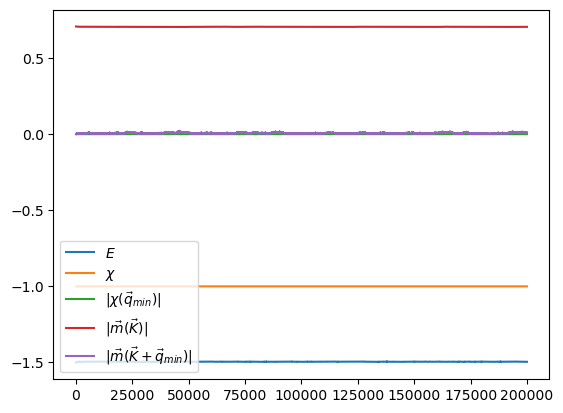

371.87236029780735

In [8]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

120° Néel state as initial state ($\chi=1$)

In [9]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

conf = Configuration(L1, L2, 1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:02:31


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0207875
  UpdateSingleSpin{true} => 0.0293197

min_energy(sim) / (L1 * L2) = -1.5
avg_energy(sim) / (L1 * L2) = -1.4950249016401709
var_energy(sim) / (L1 * L2) = 0.0003594310724007158
specific_heat(sim) / (L1 * L2) = 0.7441346861014608
avg_chirality(sim) = 1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 100.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 5.486221815636992e16
susc_spin_K(sim) / (L1 * L2) = 49.66907484747654
binder_spin_K(sim) = 0.9999986703948647
corr_length_spin_K(sim) = 248.8538439467925


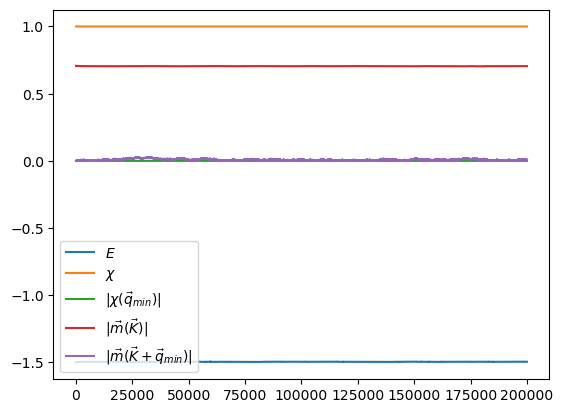

248.8538439467925

In [10]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

Random initial state

In [11]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:02:33


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.021834
  UpdateSingleSpin{true} => 0.0312926

min_energy(sim) / (L1 * L2) = -1.4052129028512832
avg_energy(sim) / (L1 * L2) = -1.398252820460318
var_energy(sim) / (L1 * L2) = 0.022835873538219306
specific_heat(sim) / (L1 * L2) = 3003.6931941221055
avg_chirality(sim) = 0.1833322916666667
var_chirality(sim) = 0.010277027710293296
susc_chirality(sim) / (L1 * L2) = 3.3716345938223373
binder_chirality(sim) = 0.7415561427790358
susc_spin_K(sim) / (L1 * L2) = 24.012050114517265
binder_spin_K(sim) = 0.9456893662903503
corr_length_spin_K(sim) = 8.899073190101547


sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


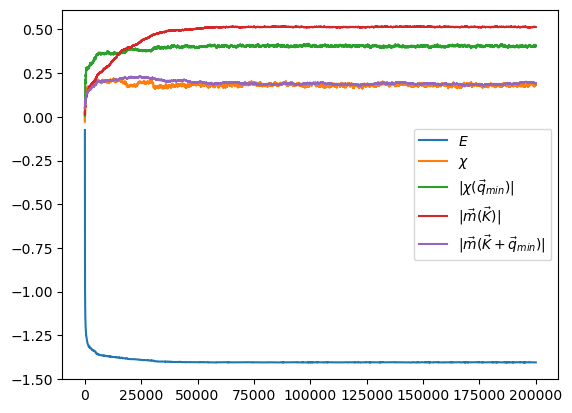

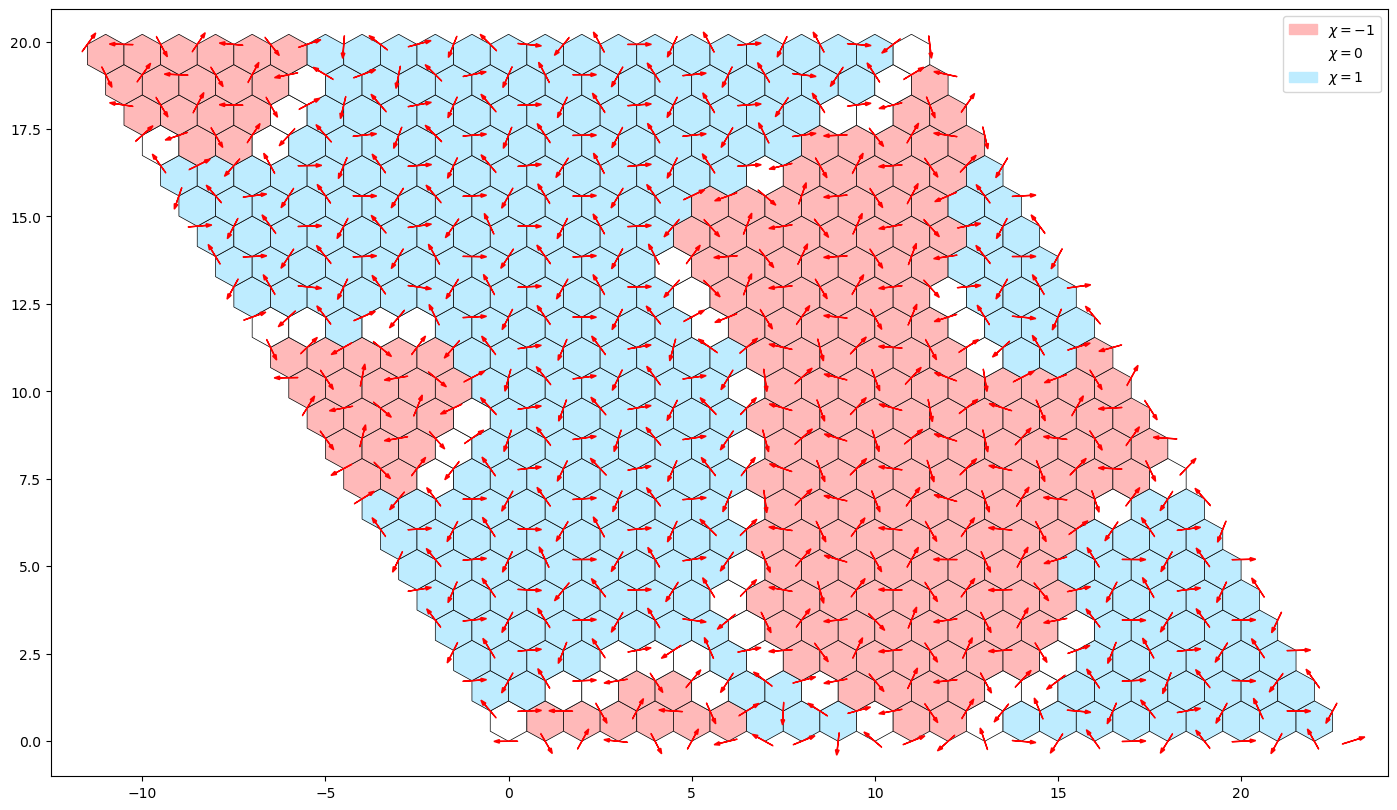

In [16]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
#@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.01.pdf")

In [18]:
@show min_energy(sim)
@show avg_energy(sim, 100000:200000) / (L1 * L2)
@show var_energy(sim, 100000:200000) / (L1 * L2)
@show specific_heat(sim, 100000:200000) / (L1 * L2)
@show avg_chirality(sim, 100000:200000)
@show var_chirality(sim, 100000:200000)
@show susc_chirality(sim, 100000:200000) / (L1 * L2)
@show binder_chirality(sim, 100000:200000)
#@show corr_length_chirality(sim, 100000:200000)
@show susc_spin_K(sim, 100000:200000) / (L1 * L2)
@show binder_spin_K(sim, 100000:200000)
@show corr_length_spin_K(sim, 100000:200000)

min_energy(sim) = -809.4026320423391
avg_energy(sim, 100000:200000) / (L1 * L2) = -1.4042497040241337
var_energy(sim, 100000:200000) / (L1 * L2) = 0.0002983527325901911
specific_heat(sim, 100000:200000) / (L1 * L2) = 0.5127175447543979
avg_chirality(sim, 100000:200000) = 0.18144129322595678
var_chirality(sim, 100000:200000) = 0.006094630052492466
susc_chirality(sim, 100000:200000) / (L1 * L2) = 3.2958087031542878
binder_chirality(sim, 100000:200000) = 0.7466249890840446
susc_spin_K(sim, 100000:200000) / (L1 * L2) = 26.418687479055365
binder_spin_K(sim, 100000:200000) = 0.9999892527229604
corr_length_spin_K(sim, 100000:200000) = 9.722747723386881


9.722747723386881

Random initial state, higher temperature

In [20]:
T = 0.1

n_cycles = 250000
n_warmup_cycles = 0
cycle_length = 50

# seed = 127459: Fully polarized solution after ~200000 cycles
rng = MersenneTwister(127459)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:03:02


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0678617
  UpdateSingleSpin{true} => 0.0967548

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


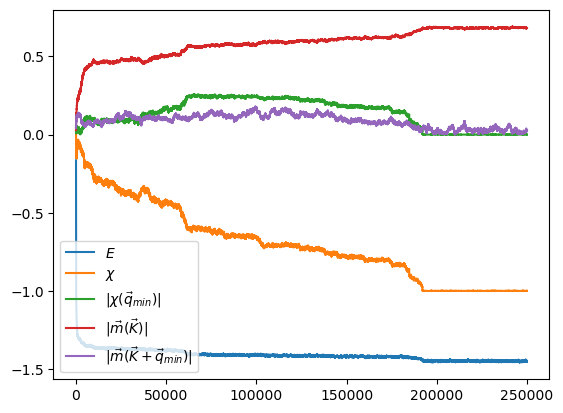

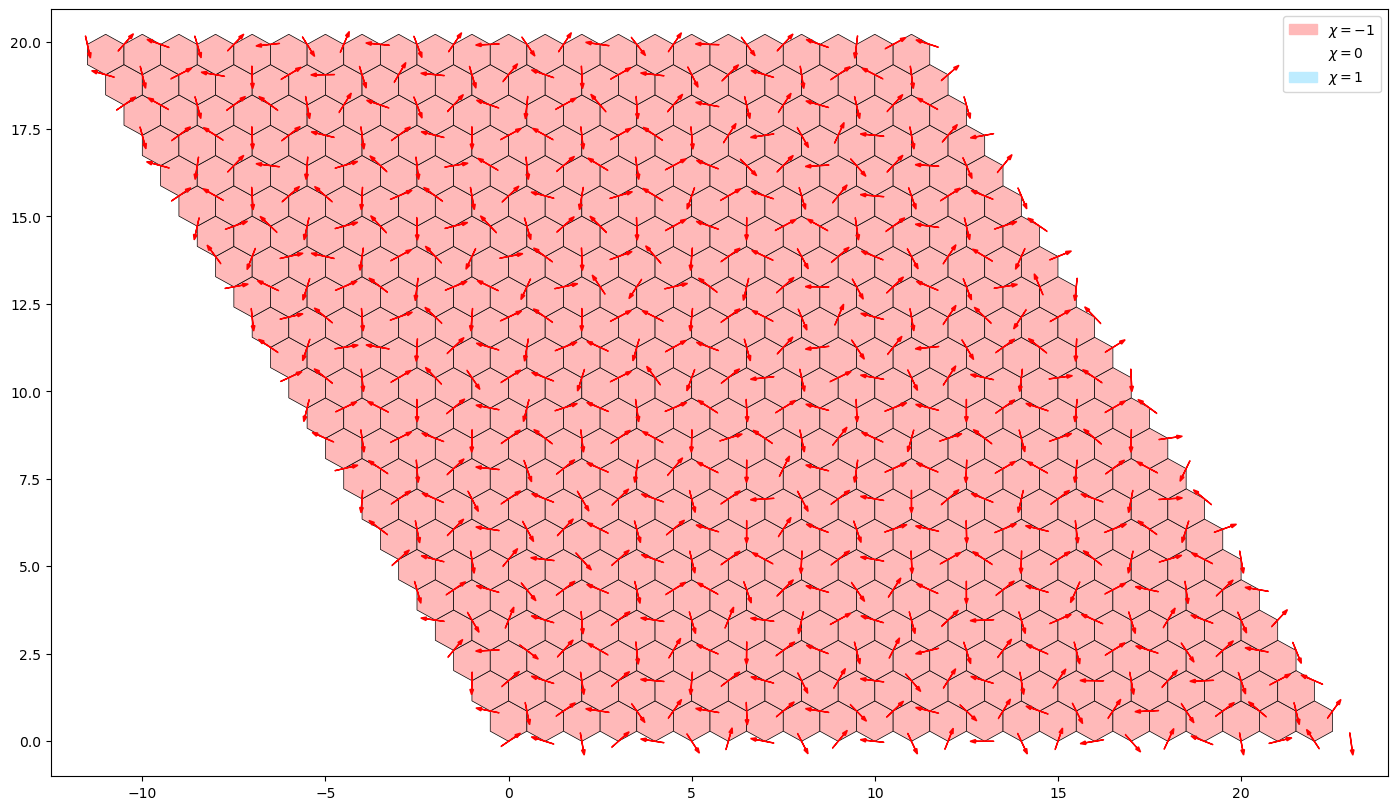

In [21]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.1.pdf")

In [22]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim, 200000:250000) / (L1 * L2)
@show var_energy(sim, 200000:250000) / (L1 * L2)
@show specific_heat(sim, 100000:200000) / (L1 * L2)
@show avg_chirality(sim, 200000:250000)
@show var_chirality(sim, 200000:250000)
@show susc_chirality(sim, 200000:250000) / (L1 * L2)
@show binder_chirality(sim, 200000:250000)
@show corr_length_chirality(sim, 200000:250000)
@show susc_spin_K(sim, 200000:250000) / (L1 * L2)
@show binder_spin_K(sim, 200000:250000)
@show corr_length_spin_K(sim, 200000:250000)

min_energy(sim) / (L1 * L2) = -1.457663030162404
avg_energy(sim, 200000:250000) / (L1 * L2) = -1.4486232533116778
var_energy(sim, 200000:250000) / (L1 * L2) = 0.0029619288936492943
specific_heat(sim, 100000:200000) / (L1 * L2) = 5.574868331981027
avg_chirality(sim, 200000:250000) = -0.9999307305520564
var_chirality(sim, 200000:250000) = 0.0003461268392079156
susc_chirality(sim, 200000:250000) / (L1 * L2) = 9.998615857037604
binder_chirality(sim, 200000:250000) = 0.7499996411644376
corr_length_chirality(sim, 200000:250000) = 10934.919134917844
susc_spin_K(sim, 200000:250000) / (L1 * L2) = 4.65909652855407
binder_spin_K(sim, 200000:250000) = 0.9999386970867006
corr_length_spin_K(sim, 200000:250000) = 81.03195067617254


81.03195067617254

New triangle update

Running MC simulation 100%|██████████████████████████████| Time: 0:00:14


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.025222046233734988, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.03444058623976113)
avg_chirality(sim) = 0.1927600694444445
var_chirality(sim) = 0.022610958952580903
susc_chirality(sim) = 2169.6580381944445
binder_chirality(sim) = 0.7230647208810631
susc_spin_K(sim) = 5023.149415344035
binder_spin_K(sim) = 0.7363858049888887
corr_length_spin_K(sim) = 4.20113534072565
susc_spin_K(sim) = 5023.149415344035
binder_spin_K(sim) = 0.7363858049888887
corr_length_spin_K(sim) = 4.20113534072565


sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


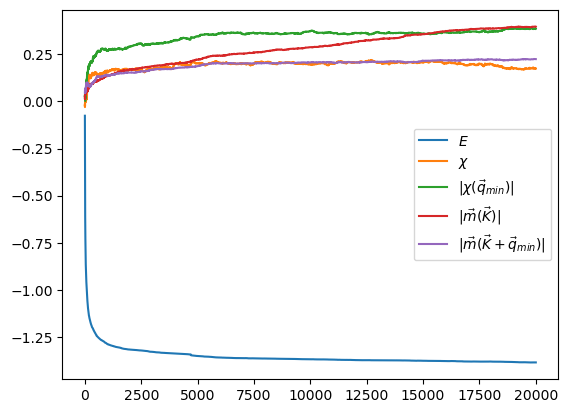

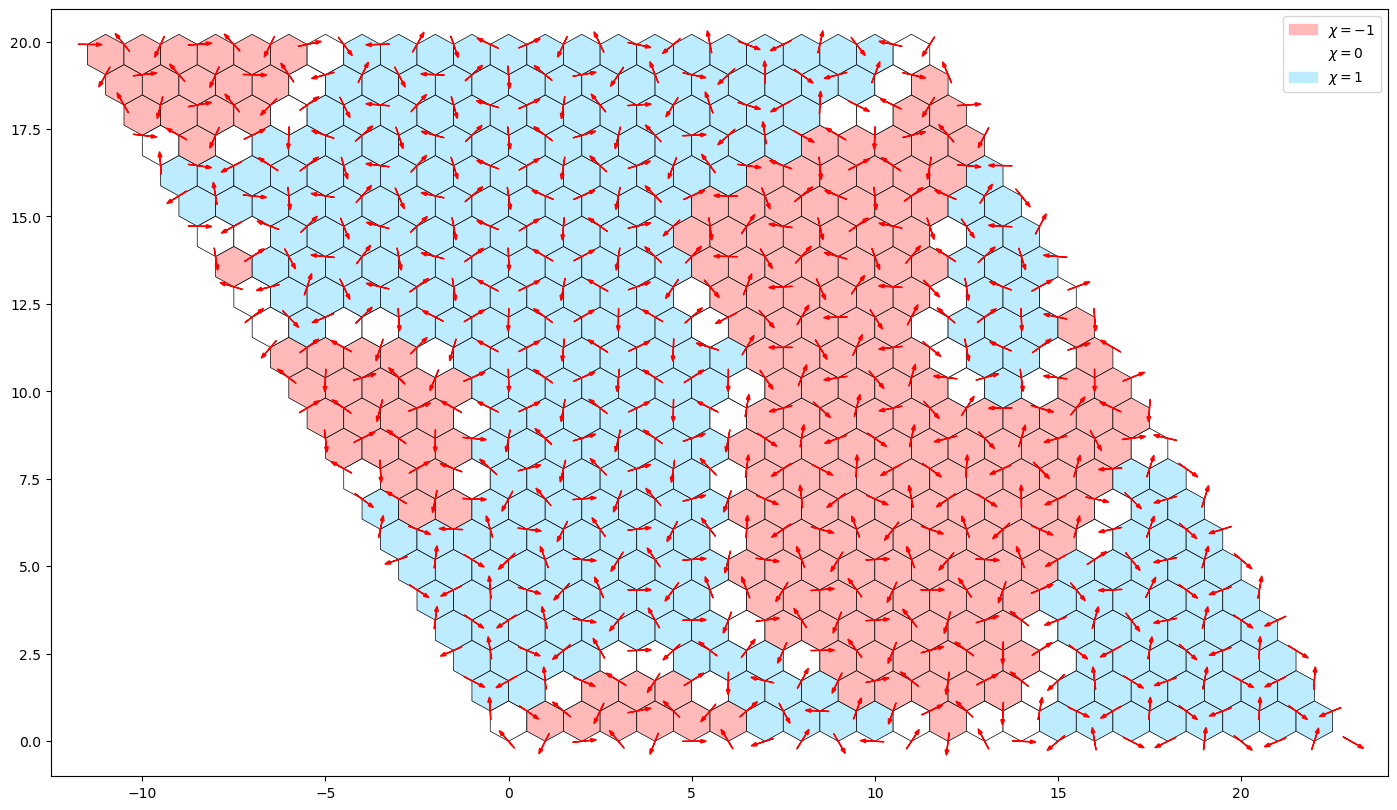

In [23]:
T = 0.01

n_cycles = 20000
n_warmup_cycles = 0
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)

@show acceptance_rates(sim)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim)
@show binder_chirality(sim)
@show susc_spin_K(sim)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)
@show susc_spin_K(sim)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("conf_new_update.pdf")

## Temperature scan

In [25]:
# Cluster size
L1, L2 = 24, 24

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
# RKKY parameters
Vpar = 0.0
Vperp = 0.0
λ = 0.1

# Temperature range
T_range = 0.05:0.05:2.0

n_cycles = 50000 #200000
n_warmup_cycles = 0
cycle_length = 50

E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))
χ_at_q_min = zeros(ComplexF64, n_cycles, length(T_range))
m_at_K = zeros(ComplexF64, 3, n_cycles, length(T_range))
m_at_K_q_min = zeros(ComplexF64, 3, n_cycles, length(T_range))

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, -1)

for (n, T) in enumerate(T_range)
    @show T
    sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
    run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true)
    @show acceptance_rates(sim)

    E[:, n] = sim.measurements.energy
    χ[:, n] = sim.measurements.chirality
    χ_at_q_min[:, n] = sim.measurements.chirality_at_q_min
    m_at_K[:, :, n] = sim.measurements.magnetization_at_K
    m_at_K_q_min[:, :, n] = sim.measurements.magnetization_at_K_q_min

    conf = deepcopy(sim.conf)
end

write("heisenberg_T_scan_E.dat", E)
write("heisenberg_T_scan_chi.dat", χ)
write("heisenberg_T_scan_chi_at_q_min.dat", χ_at_q_min)
write("heisenberg_T_scan_m_at_K.dat", m_at_K)
write("heisenberg_T_scan_m_at_K_q_min.dat", m_at_K_q_min)

T = 0.05


Running MC simulation 100%|██████████████████████████████| Time: 0:00:28


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.04707573191773857, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.06619690331262268)
T = 0.1


Running MC simulation 100%|██████████████████████████████| Time: 0:00:34


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.06651051617596508, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.09498029614892609)
T = 0.15


Running MC simulation 100%|██████████████████████████████| Time: 0:00:33


... (72 outputs left out)

acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.5353248022820696, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.6539822662795358)
T = 2.0


Running MC simulation 100%|██████████████████████████████| Time: 0:00:41


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.5414836310000962, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.6601970047598227)


96000000

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


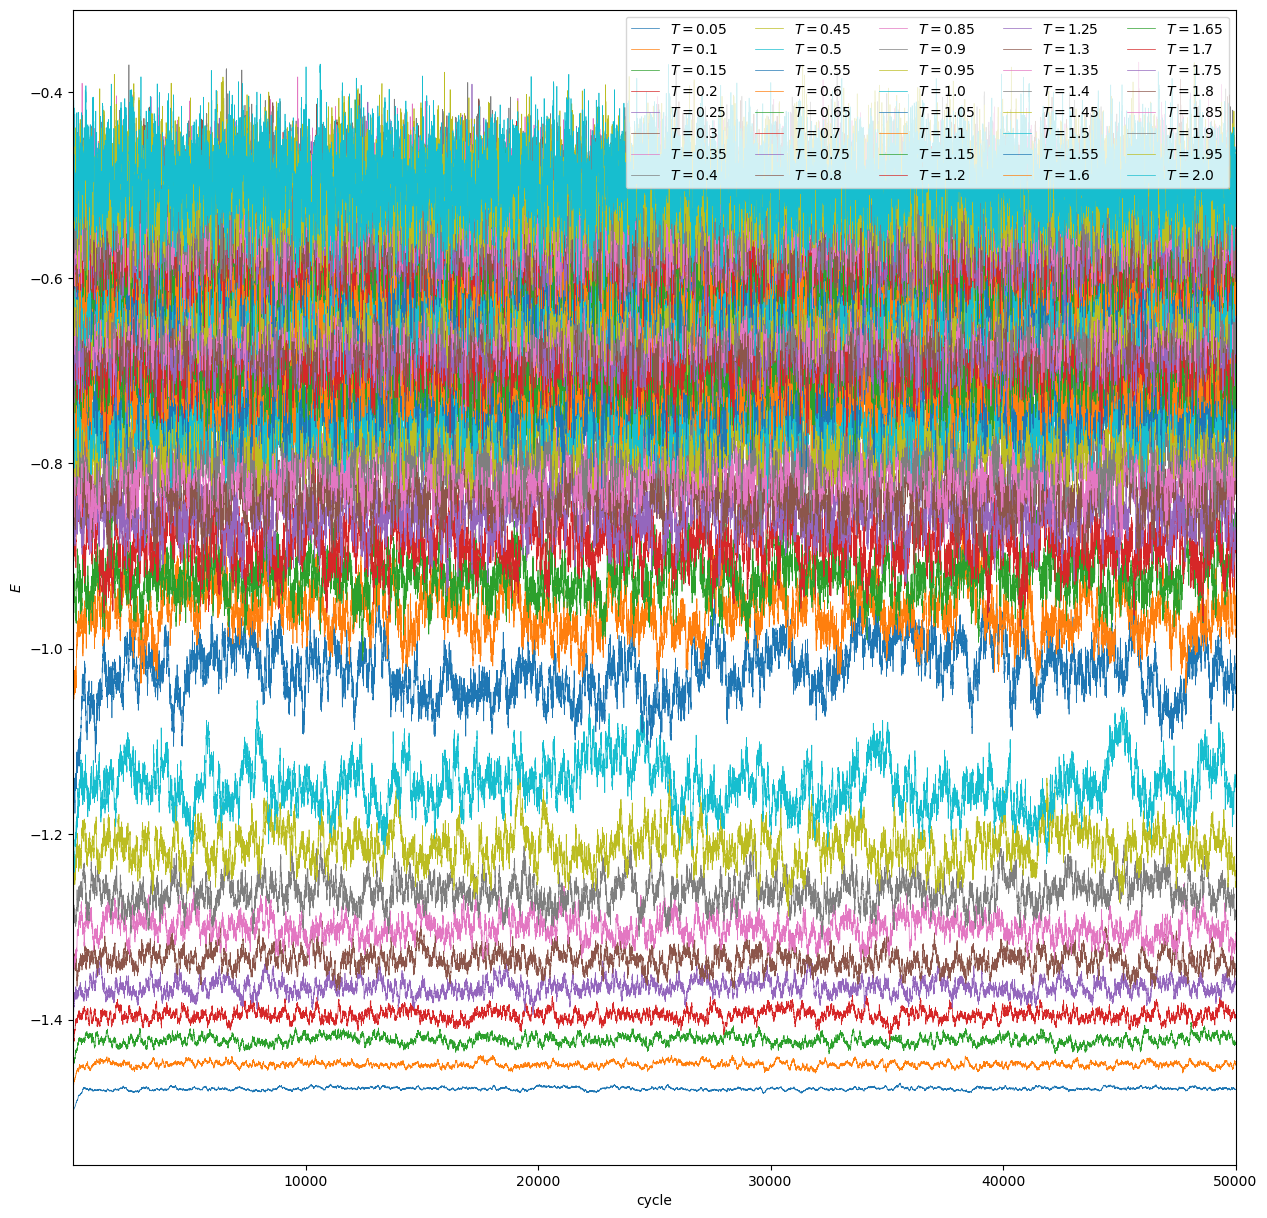

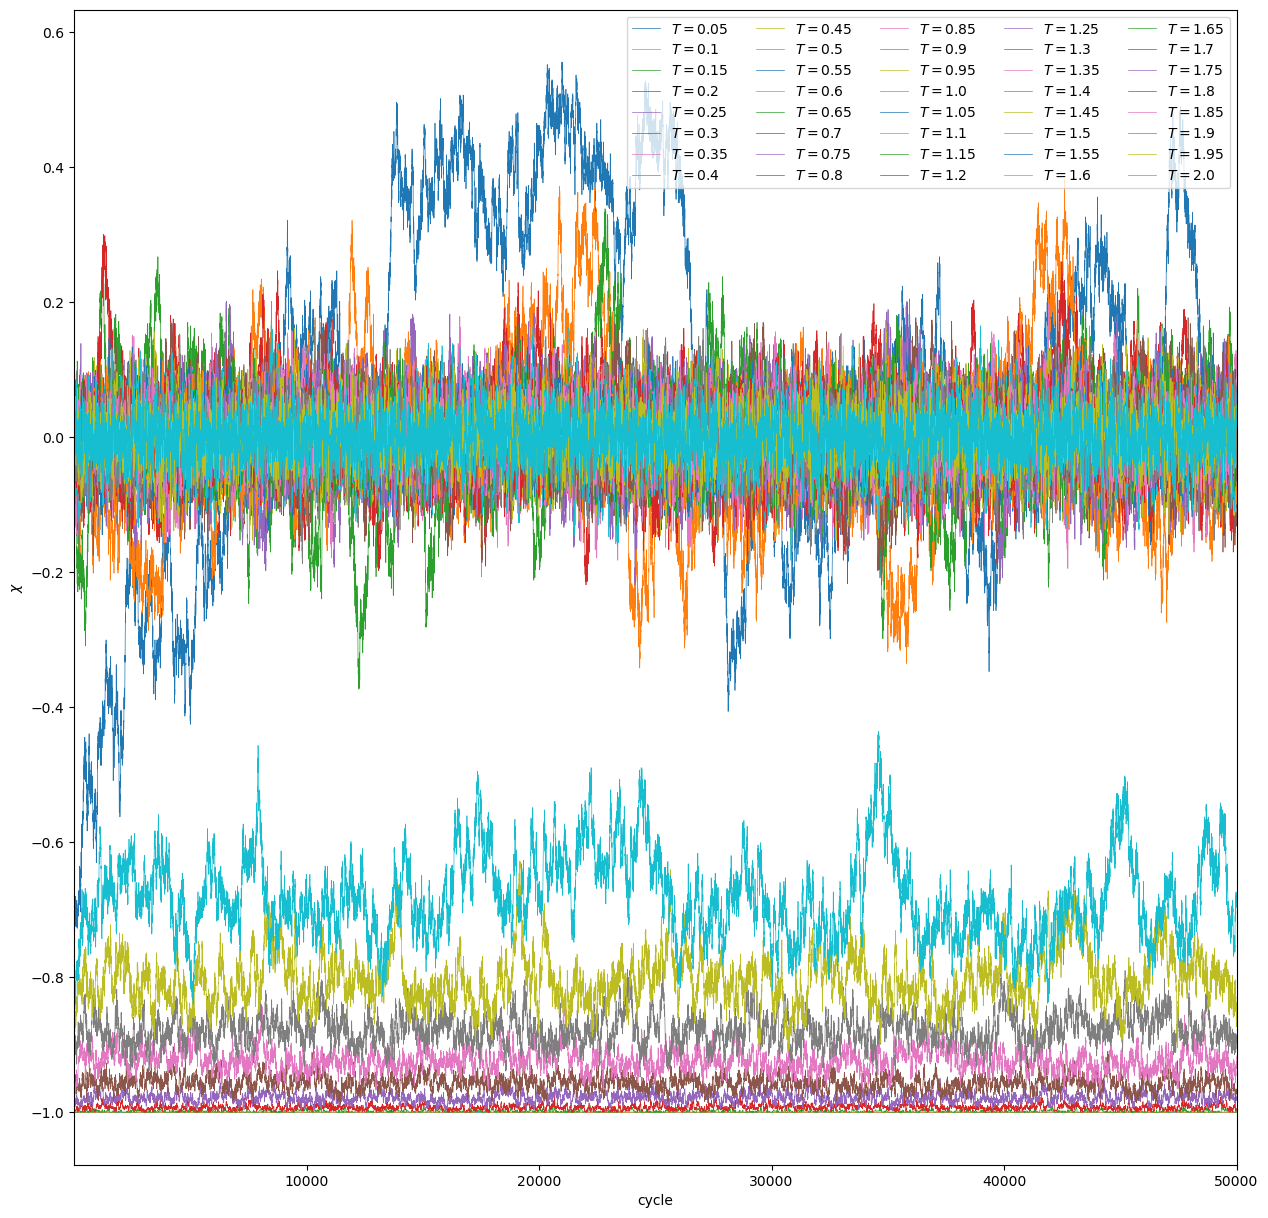

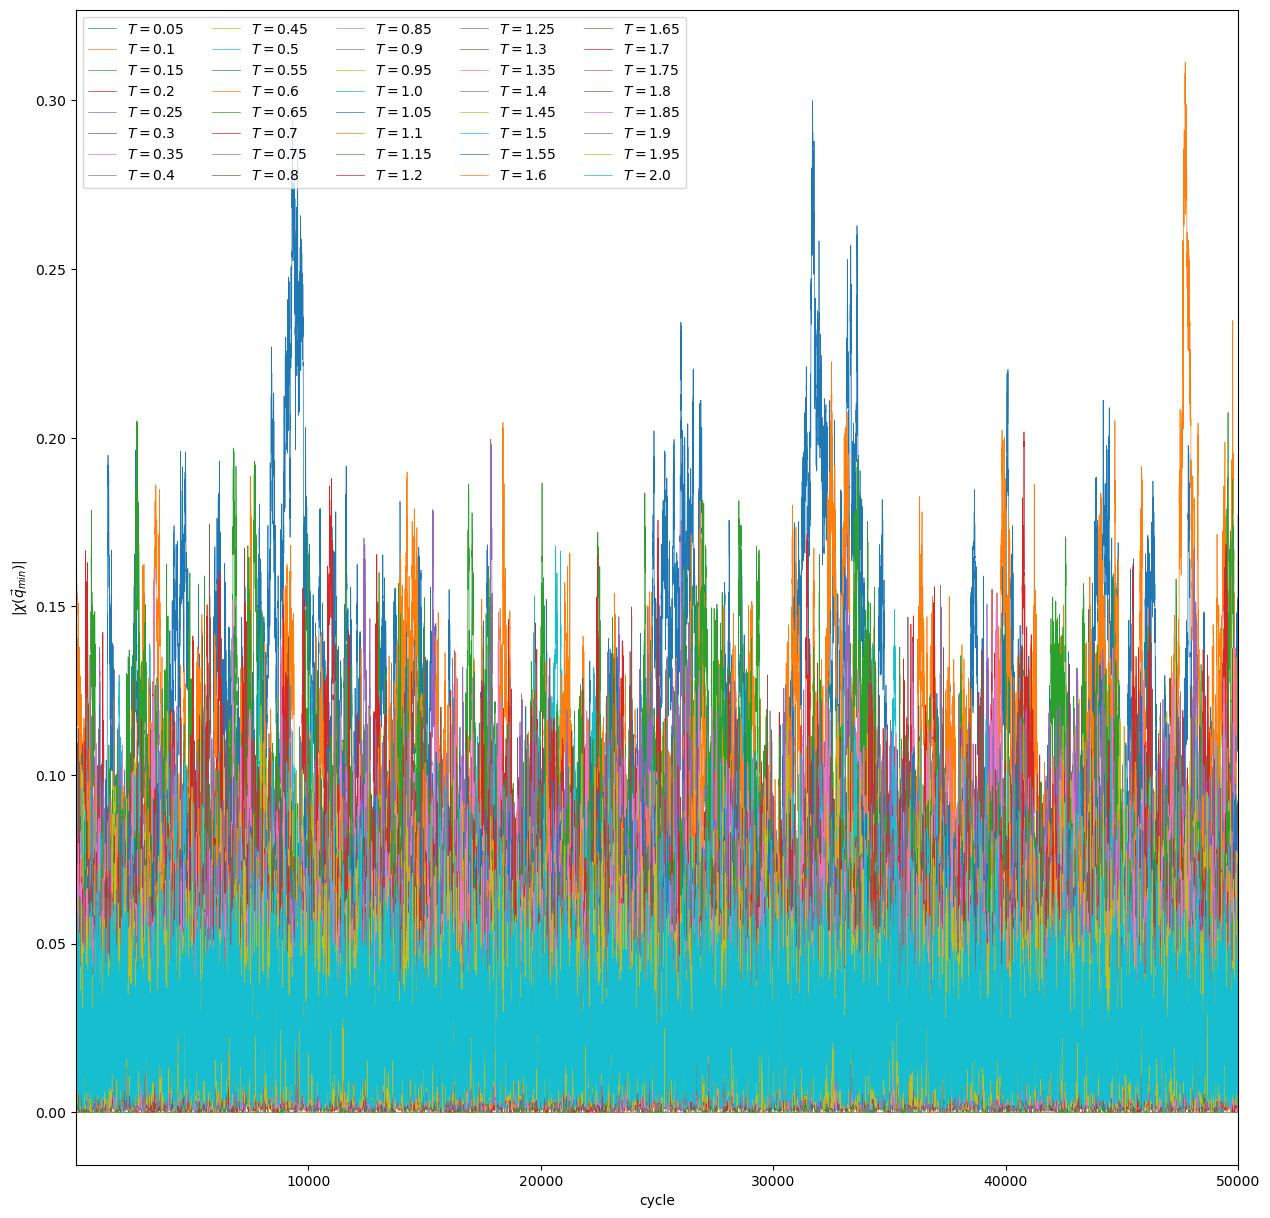

In [26]:
plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(E[:, n] / (L1 * L2), label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_cycles))
plt.xlabel("cycle")
plt.ylabel(raw"$E$")
plt.legend(loc="best", ncol=5)
plt.show()

plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(χ[:, n], label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_cycles))
plt.xlabel("cycle")
plt.ylabel(raw"$\chi$")
plt.legend(loc="best", ncol=5)
plt.show()

plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(abs.(χ_at_q_min[:, n]), label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_cycles))
plt.xlabel("cycle")
plt.ylabel(raw"$|\chi(\vec{q}_{min})|$")
plt.legend(loc="best", ncol=5)
plt.show()

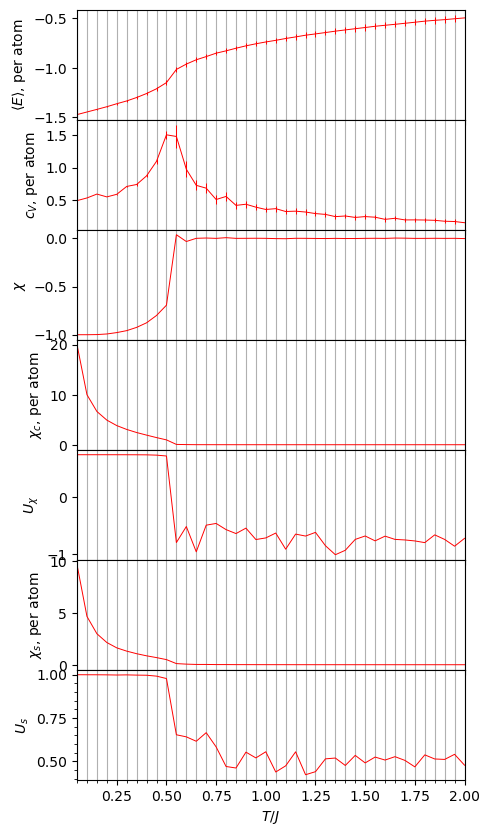

In [38]:
first_cycle = 25_000 #100_000
last_cycle = 50_000 #200_000

E_avg = [avg_energy(E[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
E_var = [var_energy(E[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
cV = [specific_heat(E[:, n], 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]

χ_avg = [avg_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_var = [var_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_susc = [susc_chirality(χ[:, n], L1 * L2, 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_binder = [binder_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
#χ_cl = [corr_length_chirality(χ[:, n], χ_at_q_min[:, n], L1, first_cycle:last_cycle) for n in 1:length(T_range)]

m_susc = [susc_spin_K(m_at_K[:, :, n], L1 * L2, 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]
m_binder = [binder_spin_K(m_at_K[:, :, n], first_cycle:last_cycle) for n in 1:length(T_range)]
m_cl = [corr_length_spin_K(m_at_K[:, :, n], m_at_K_q_min[:, :, n], L1, first_cycle:last_cycle) for n in 1:length(T_range)]

plt.figure(figsize=(5, 10))
gs = plt.matplotlib.gridspec.GridSpec(7, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), cV / (L1 * L2), yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$c_V$, per atom")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), χ_avg, lw=0.7, color="red")
ax3.set_ylabel(raw"$\chi$")
plt.setp(ax3.get_xticklabels(), visible=false)
ax3.grid(axis="x", which="both")

ax4 = plt.subplot(gs[4], sharex=ax1)
ax4.plot(collect(T_range), χ_susc / (L1 * L2), lw=0.7, color="red")
ax4.set_ylabel(raw"$\chi_c$, per atom")
plt.setp(ax4.get_xticklabels(), visible=false)
ax4.grid(axis="x", which="both")

ax5 = plt.subplot(gs[5], sharex=ax1)
ax5.plot(collect(T_range), χ_binder, lw=0.7, color="red")
ax5.set_ylabel(raw"$U_\chi$")
plt.setp(ax5.get_xticklabels(), visible=false)
ax5.grid(axis="x", which="both")

ax6 = plt.subplot(gs[6], sharex=ax1)
ax6.plot(collect(T_range), m_susc / (L1 * L2), lw=0.7, color="red")
ax6.set_ylabel(raw"$\chi_s$, per atom")
plt.setp(ax6.get_xticklabels(), visible=false)
ax6.grid(axis="x", which="both")

ax7 = plt.subplot(gs[7], sharex=ax1)
ax7.plot(collect(T_range), m_binder, lw=0.7, color="red")
ax7.set_ylabel(raw"$U_s$")
ax7.grid(axis="x", which="both")

ax7.set_xlim((first(T_range), last(T_range)))
ax7.set_xlabel(raw"$T/J$")
ax7.minorticks_on()
plt.show()